# Module 0 · The Loop
**Baseline: machine learning for software developers**

Every technique in the song was trained the same way: show the model examples, score how wrong it is, nudge the numbers to be less wrong, and repeat. This notebook builds that loop by hand, then lets PyTorch do the calculus.

You will learn: **model, parameters, loss, gradient descent, autograd, classification (softmax and cross-entropy), mini-batches and epochs, optimizers, tensor shapes, train/validation/test splits, overfitting, benchmarks.** Every later module assumes these.

> Developer translation: a *model* is a function with tunable constants. *Training* is an automated search for constants that make a test suite pass. The *loss* is that test suite, made differentiable so the search knows which way to move.



In [1]:
import sys; sys.path.insert(0, '.')
from blcourse import *
import matplotlib.pyplot as plt
hardware_report()



python 3.11.15 · torch 2.15.0 · arm64 · 64 GB RAM
DEVICE = 'mps'   TIER = 'laptop'   (override: BASELINE_TIER / BASELINE_DEVICE)


### Setup: the hardware switch
Every lab in the course reads its sizes from one table, `CFG`. Your tier was detected above:

| tier | for | what changes |
|---|---|---|
| `laptop` | any modern laptop | small models, data subsets; every lab finishes in minutes |
| `mac-max` | M-series Max/Ultra, ≥ 32 GB | wider/deeper nets, full datasets, a 1.5B LLM |
| `cuda` | NVIDIA GPU, ≥ 12 GB | biggest configs, a 7B LLM |

To force a tier, restart the kernel with `BASELINE_TIER=laptop jupyter lab` (or set `os.environ['BASELINE_TIER']` before the import).



In [2]:
CFG



{'cifar_train': 20000,
 'cifar_epochs': 8,
 'cnn_width': 32,
 'resnet': False,
 'text_chars': 1000000,
 'gpt': {'n_layer': 4,
  'n_head': 4,
  'n_embd': 128,
  'block': 128,
  'steps': 1500,
  'batch': 32},
 'lstm': {'hidden': 256, 'steps': 1500, 'batch': 32, 'block': 128},
 'scaling_widths': [32, 48, 64, 96, 128],
 'scaling_steps': 600,
 'gan_steps': 3000,
 'ddpm_steps': 4000,
 'llm': 'Qwen/Qwen2.5-0.5B-Instruct',
 'llm_dtype': 'float32',
 'lora_steps': 60,
 'dpo_steps': 40,
 'niah_lengths': [256, 512, 1024, 2048],
 'niah_depths': [0.0, 0.25, 0.5, 0.75, 1.0],
 'attn_lengths': [256, 512, 1024, 2048]}

<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">



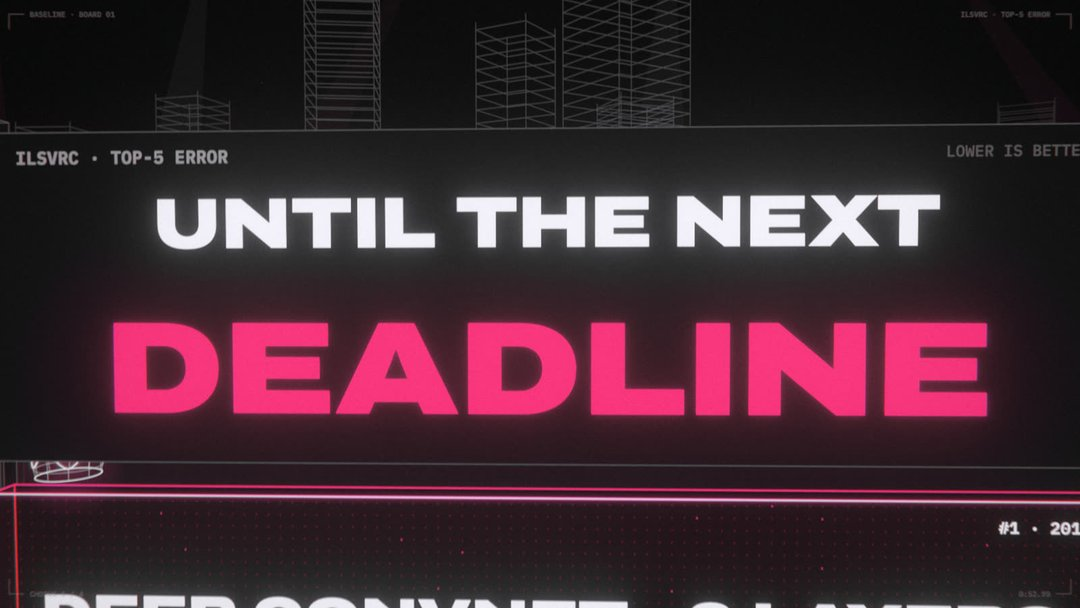

In [3]:
still(52.8)



## 0.0 Why not just write the program?
Before any ML, try the obvious approach. scikit-learn ships 1,797 small handwritten digits (8 × 8 pixels, values 0–16; no download needed). Your job: write `classify(img)` by hand. Below is a first attempt with six rules a programmer might write. Run it, then try to improve it.



hand-written rules: 36% correct
per digit: 0:88%  1:78%  2:0%  3:12%  4:0%  5:0%  6:78%  7:48%  8:30%  9:29%


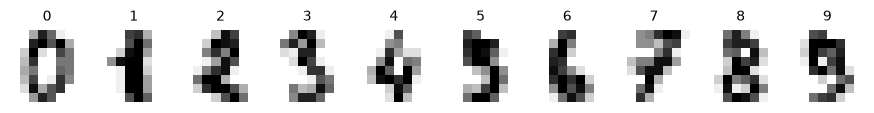

In [4]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
digits = load_digits()
imgs, labels = digits.images, digits.target

fig, axes = plt.subplots(1, 10, figsize=(10, 1.3))
for d, ax in enumerate(axes):
    ax.imshow(imgs[np.where(labels == d)[0][0]], cmap='gray_r'); ax.set_title(str(d), fontsize=9); ax.axis('off')

def classify(img):
    """Hand-written rules. Each one is reasonable; together they still fail."""
    ink = img.sum()
    center = img[3:5, 3:5].sum()
    top, bottom = img[:3].sum(), img[5:].sum()
    left, right = img[:, :4].sum(), img[:, 4:].sum()
    if center < 10 and ink > 250: return 0            # a ring with an empty middle
    if img[:, 3:5].sum() > 0.55 * ink: return 1        # mostly one vertical stroke
    if top > 1.6 * bottom: return 7                    # heavy on top
    if bottom > 1.4 * top: return 6                    # heavy at the bottom
    if right > 1.5 * left: return 9
    return 8 if ink > 330 else 3

rule_pred = np.array([classify(i) for i in imgs])
print(f'hand-written rules: {(rule_pred == labels).mean():.0%} correct')
print('per digit:', '  '.join(f'{d}:{(rule_pred[labels == d] == d).mean():.0%}' for d in range(10)))



Every rule makes sense, and the program still misses most digits: it never even outputs a 2, 4 or 5. Fix one digit and you break another. Now flip the approach. Keep a fixed *template*: give each of the 10 digits a score equal to a weighted sum of the 64 pixels, and pick the highest score. That leaves 64 × 10 weights + 10 biases = 650 blank numbers. Then let an algorithm fill in the blanks from labeled examples. We train on 70% of the digits and test on the other 30%, which it never saw.



learned template: 95% correct on digits it never saw


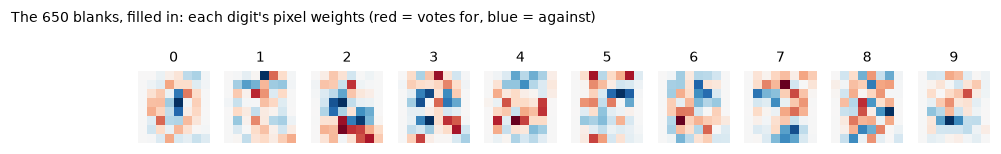

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(imgs.reshape(len(imgs), -1), labels, test_size=0.3, random_state=0)
learned = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
print(f'learned template: {learned.score(Xte, yte):.0%} correct on digits it never saw')

fig, axes = plt.subplots(1, 10, figsize=(10, 1.6))
for d, ax in enumerate(axes):
    w = learned.coef_[d].reshape(8, 8); lim = np.abs(w).max()
    ax.imshow(w, cmap='RdBu_r', vmin=-lim, vmax=lim); ax.set_title(str(d), fontsize=9); ax.axis('off')
fig.suptitle("The 650 blanks, filled in: each digit's pixel weights (red = votes for, blue = against)",
             x=0.01, y=1.04, ha='left', fontsize=9);



Those ten little images *are* the program. Nobody wrote them; an algorithm found them by following the gradient of the error, which is the subject of the rest of this module.

**The road not taken.** You could also search for programs by evolution: mutate candidates, keep the fittest (genetic algorithms, genetic programming). That works for a handful of knobs, but each try only says "better or worse", so the number of tries explodes as knobs grow. The gradient gives a direction for all 650 knobs (or 175 billion) from one pass over the data.

### Try it
Spend five minutes improving `classify`. How far can you get? Then imagine doing it for 28 × 28 photos of street signs.



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 0.1 A model is a function with knobs
Here is the smallest useful model: a line, ŷ = w·x + b, with two **parameters** w and b. The data is noisy points from a line we pretend not to know.



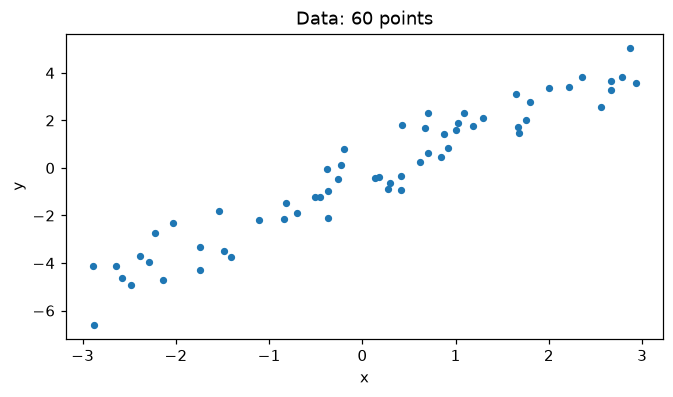

In [6]:
seed(0)
x = np.random.uniform(-3, 3, 60)
y = 1.7 * x - 0.4 + np.random.normal(0, 0.8, x.shape)

fig, ax = plt.subplots()
ax.scatter(x, y, s=14)
ax.set(title='Data: 60 points', xlabel='x', ylabel='y');



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 0.2 The loss is a test suite that returns a number
A unit test passes or fails. A **loss** tells you *how badly* the model fails, as one smooth number. Mean squared error is the classic choice:

$$L(w, b) = \frac{1}{N}\sum_i (w x_i + b - y_i)^2$$

Because L is smooth, its **gradient** ∂L/∂w, ∂L/∂b points uphill. Step the other way and the loss goes down. That step, repeated, is **gradient descent**:

$$w \leftarrow w - \eta \,\frac{\partial L}{\partial w}$$

η (eta) is the **learning rate**: the step size.



learned w=1.604 b=-0.360   (truth: 1.7, -0.4)


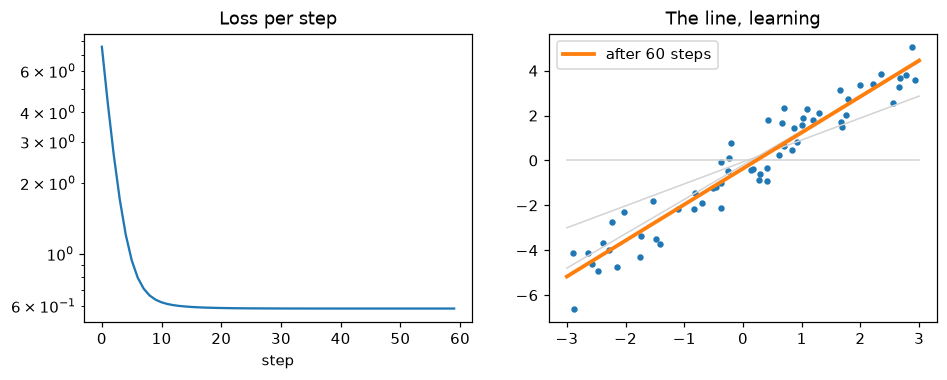

In [7]:
def loss_and_grads(w, b):
    err = w * x + b - y
    return (err ** 2).mean(), (2 * err * x).mean(), (2 * err).mean()   # derived by hand

w, b, lr = 0.0, 0.0, 0.05
trace = []
for step in range(60):
    L, dw, db = loss_and_grads(w, b)
    trace.append((w, b, L))
    w, b = w - lr * dw, b - lr * db
print(f'learned w={w:.3f} b={b:.3f}   (truth: 1.7, -0.4)')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.plot([t[2] for t in trace]); a1.set(title='Loss per step', xlabel='step', yscale='log')
xs = np.linspace(-3, 3, 2)
for i in (0, 3, 10):
    a2.plot(xs, trace[i][0] * xs + trace[i][1], c='lightgray', lw=1)
a2.scatter(x, y, s=10, c='C0'); a2.plot(xs, w * xs + b, c='C1', lw=2.5, label='after 60 steps')
a2.set(title='The line, learning'); a2.legend();



### Try it
Change `lr` to `0.2`, then `0.4`, and rerun. What happens to the loss curve? (Too-large learning rates are the most common reason training "explodes".)

<details><summary>Answer</summary>

At 0.2 it converges faster. At 0.4 each step overshoots the minimum by more than it corrects, so w oscillates with growing amplitude and the loss climbs to infinity. The safe step size depends on the curvature of the loss. That is why optimizers like Adam adapt it per parameter.
</details>



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 0.3 Autograd: never derive a gradient by hand again
Deriving `dw` by hand works for two parameters. GPT-3 has 175 billion. PyTorch records every operation you do on a tensor marked `requires_grad=True`, then `loss.backward()` walks that record backwards with the chain rule (**backpropagation**, Module 1) and fills in `.grad`.



In [8]:
X, Y = torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
w = torch.zeros((), requires_grad=True)
b = torch.zeros((), requires_grad=True)
opt = torch.optim.SGD([w, b], lr=0.05)          # the update rule above, packaged
for step in range(60):
    loss = ((w * X + b - Y) ** 2).mean()
    opt.zero_grad()
    loss.backward()                              # fills w.grad, b.grad
    opt.step()
print(f'autograd: w={w.item():.3f} b={b.item():.3f}')



autograd: w=1.604 b=-0.360


That five-line loop (**forward → loss → zero_grad → backward → step**) is the heartbeat of every model in this course, from the 1958 perceptron to a 7B LLM. Only the model and the loss change.



### Your turn: check a gradient numerically
Before autograd, people checked hand-derived gradients by measuring the slope directly: nudge w a tiny amount `eps` each way and compute rise over run, (f(w + eps) − f(w − eps)) / (2·eps). Write it. The check compares your slope with known derivatives and with autograd.



In [9]:
def numeric_grad(f, w, eps=1e-5):
    """Slope of the one-argument function f at the number w, measured numerically."""
    raise NotImplementedError        # your code here: one line

check('numeric_grad', numeric_grad)



⏳ numeric_grad: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 0.4 From numbers to classes: scores, softmax, cross-entropy



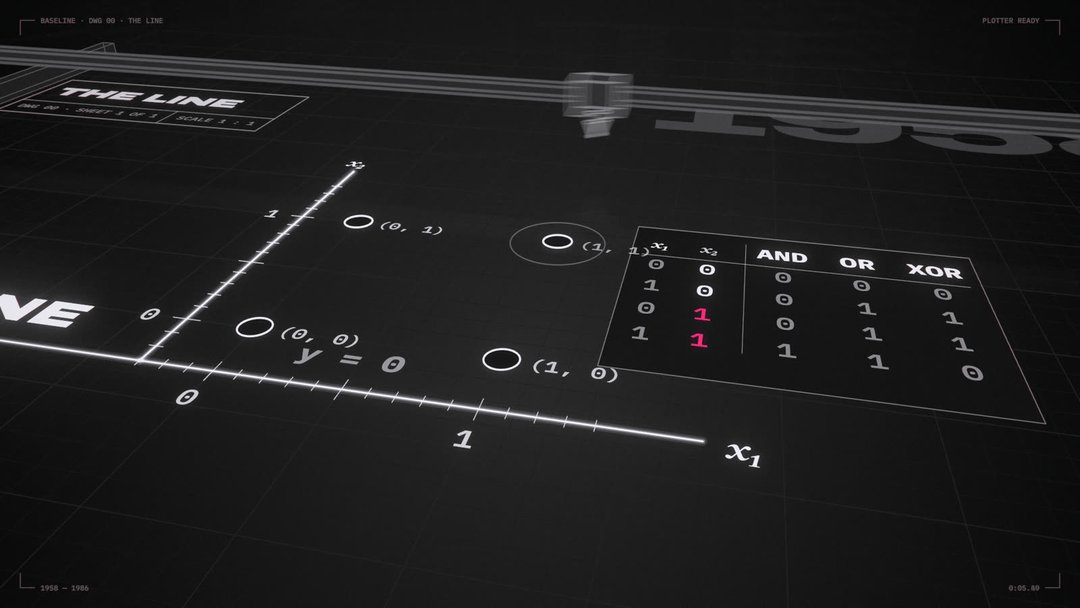

In [10]:
still(5.5)



The line predicted a *number*. Most of this course predicts a *class*: which digit, which word comes next. The recipe is the same everywhere:

1. The model outputs **one score per class**, called **logits**. For the 8 × 8 digits from §0.0, that's `nn.Linear(64, 10)`: 10 weighted sums of the 64 pixels, the template from §0.0.
2. **Softmax** turns scores into probabilities: exponentiate each score (so all are positive, and bigger scores grow much bigger), then divide by the total so they sum to 1.
3. The loss is **cross-entropy**: −log(the probability given to the correct class). If the model gave the right answer probability 1, the loss is −log 1 = 0. At 0.5 it's 0.69, and at 0.01 it's 4.6. The log turns "a bit less confident" into a smooth, steady penalty, and turns products of probabilities into sums, which is why you'll see logs everywhere.

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}} \qquad L = -\log p_{\text{correct}}$$



loss for this image = −log p(label 9) = −log 0.098 = 2.321


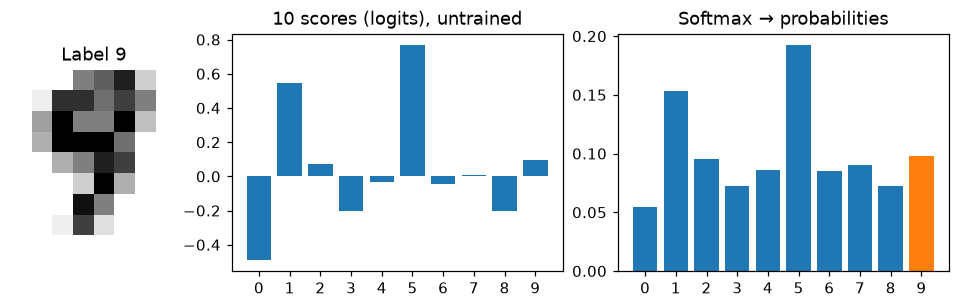

In [11]:
# the digits from §0.0 as tensors: 64 pixel values in (scaled to 0–1), one of 10 labels out
Dtr, Dte = torch.tensor(Xtr, dtype=torch.float32) / 16, torch.tensor(Xte, dtype=torch.float32) / 16
Ltr, Lte = torch.tensor(ytr), torch.tensor(yte)

seed(0)
model = nn.Linear(64, 10)                       # 10 scores per image: 64 weights + 1 bias each = 650 parameters
with torch.no_grad():
    scores = model(Dtr[:1])[0]
probs = scores.softmax(-1)
label = Ltr[0].item()
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(11, 2.8), gridspec_kw={'width_ratios': [1, 2, 2]})
a1.imshow(Dtr[0].reshape(8, 8), cmap='gray_r'); a1.set_title(f'Label {label}'); a1.axis('off')
a2.bar(range(10), scores); a2.set(title='10 scores (logits), untrained', xticks=range(10))
a3.bar(range(10), probs, color=['C1' if i == label else 'C0' for i in range(10)]); a3.set(title='Softmax → probabilities', xticks=range(10))
print(f'loss for this image = −log p(label {label}) = −log {probs[label]:.3f} = {-probs[label].log():.3f}')



### Your turn: cross-entropy from scratch
Write the loss for one example: softmax the scores, then take −log of the correct class's probability. One test feeds scores of about 1000: `exp(1000)` overflows to infinity. Find the fix. (Hint: softmax gives the same answer if you subtract the same number from every score.)



In [12]:
def cross_entropy(scores, label):
    """scores: a numpy array of K numbers; label: the index of the correct class. Return the loss (a number)."""
    raise NotImplementedError        # your code here: 2–3 lines

check('cross_entropy', cross_entropy)



⏳ cross_entropy: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


Now train the 650-number template with the five-line loop, `F.cross_entropy` as the loss. It reaches about the same accuracy as scikit-learn's version in §0.0, because it *is* the same model.



In [13]:
seed(0)
model = nn.Linear(64, 10)
opt = torch.optim.SGD(model.parameters(), lr=0.5)
for step in range(300):
    loss = F.cross_entropy(model(Dtr), Ltr)     # same loop as the line, with a classification loss
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    acc = (model(Dte).argmax(1) == Lte).float().mean().item()
print(f'train loss {loss.item():.3f} · test accuracy {acc:.1%}')



train loss 0.215 · test accuracy 94.3%


<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 0.5 The loop at scale: mini-batches, epochs, optimizers



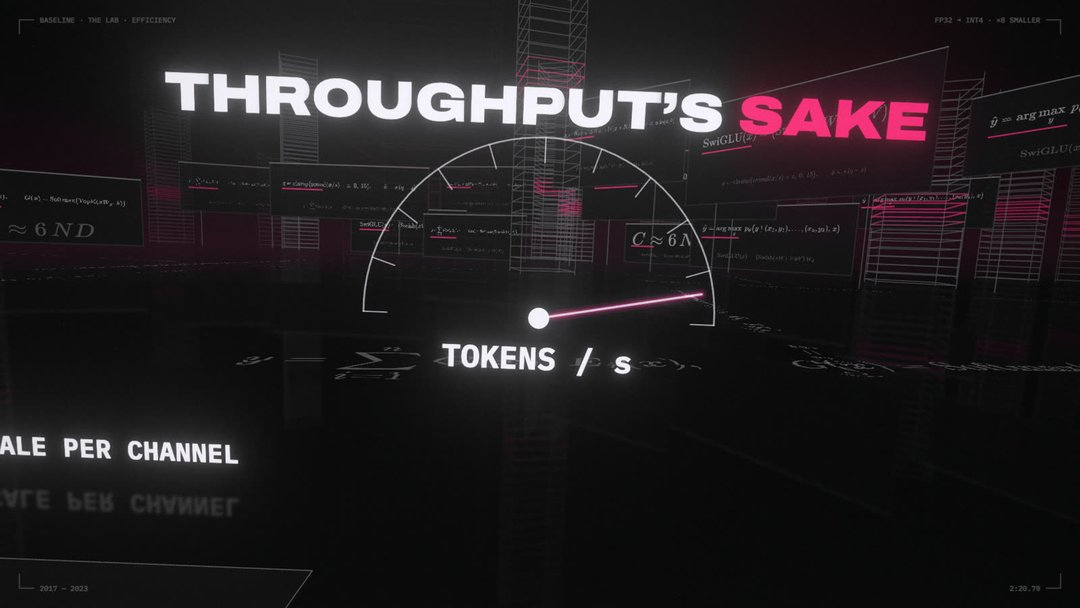

In [14]:
still(140.79)



The loop above computed the loss on **all** 1,257 training images before every step. Real datasets have millions of examples, so every lab from Module 1 on uses the same handful of additions. Here they are, one at a time:

| Piece | What it is | Why |
|---|---|---|
| **Mini-batch** | Compute the loss on a random slice (say 32 examples), then step | A cheap, noisy estimate of the full gradient. Many small steps beat a few exact ones. |
| **Epoch** | One pass over the whole training set, in mini-batches | The unit for "how long we trained" |
| **Shuffle** | A new random order every epoch | So batches differ each time and don't repeat a pattern |
| **Optimizer** | The update rule. SGD steps straight down the gradient; **Adam** keeps a running average of each parameter's gradients and scales its step | Adam works with little tuning; AdamW adds weight decay (a pull toward small weights) |
| **Learning-rate schedule** | Change the step size during training: warm up, then decay | Big steps early to move fast, small steps late to settle |
| **Augmentation** | Make extra training examples by changes that keep the label, like flipping a photo | More data, for free, against overfitting |
| **`model.eval()`, `torch.no_grad()`** | Switch to scoring mode, and skip recording gradients | Some layers (dropout, batch norm) act differently in training; no_grad saves memory and time |

These settings (batch size, learning rate, epochs…) are **hyperparameters**: knobs *you* choose, as opposed to parameters, which training learns.

> **Predict first.** Train the digit classifier for 15 epochs three ways: full batch with SGD, mini-batches of 32 with SGD, mini-batches of 32 with Adam. Which ends with the lowest test loss?



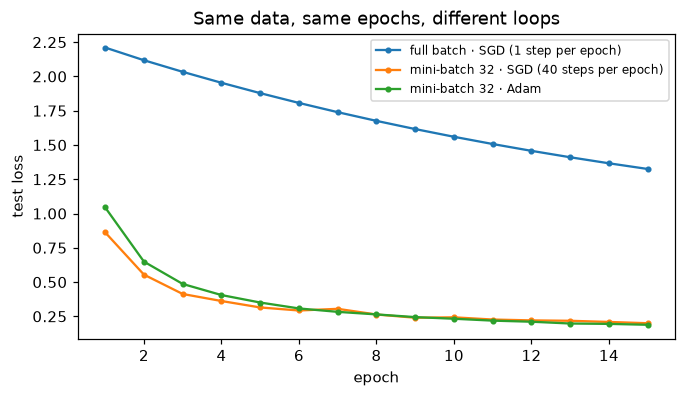

In [15]:
def run(optimizer, batch, epochs=15):
    seed(0); m = nn.Linear(64, 10)
    opt = torch.optim.SGD(m.parameters(), lr=0.5) if optimizer == 'sgd' else torch.optim.Adam(m.parameters(), lr=0.01)
    curve = []
    for epoch in range(epochs):                         # one epoch = one pass over the training set
        perm = torch.randperm(len(Dtr))                 # shuffle
        for i in range(0, len(Dtr), batch):
            idx = perm[i:i + batch]                     # one mini-batch
            loss = F.cross_entropy(m(Dtr[idx]), Ltr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():                           # scoring only: no gradients needed
            curve.append(F.cross_entropy(m(Dte), Lte).item())
    return curve

runs = {'full batch · SGD (1 step per epoch)': run('sgd', len(Dtr)),
        'mini-batch 32 · SGD (40 steps per epoch)': run('sgd', 32),
        'mini-batch 32 · Adam': run('adam', 32)}
fig, ax = plt.subplots()
for (name, curve), c in zip(runs.items(), ('C0', 'C1', 'C2')):
    ax.plot(range(1, 16), curve, 'o-', c=c, ms=3, label=name)
ax.set(xlabel='epoch', ylabel='test loss', title='Same data, same epochs, different loops'); ax.legend(fontsize=8);



Per epoch, full-batch training takes **one** step; mini-batches of 32 take about forty. Each mini-batch gradient is noisier, but you get forty of them for the same work. Adam and SGD end up close on this small model; Adam's advantage shows on deep networks, where one learning rate rarely suits every layer.

When you meet the CIFAR training loop in Module 1, every line of it is in the table above.



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 0.6 Vectors, matrices and shapes



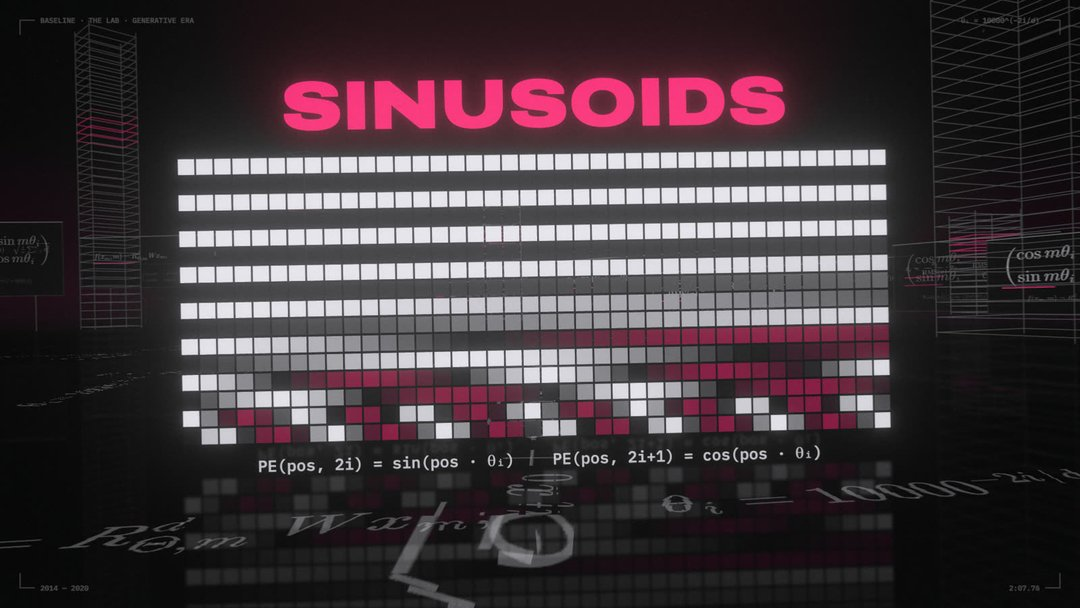

In [16]:
still(127.75)



Three facts carry most of the math in this course:

- **A vector is a list of numbers, and a dot product is a match score.** Multiply two lists position by position and add: `a @ b`. It's large when they point the same way, near 0 when unrelated, negative when opposite. The perceptron, the digit template, a convolution and attention are all dot products.
- **A matrix multiply is many dot products at once.** `x @ W` with x: (32, 64) and W: (64, 10) dots each of 32 images with each of 10 templates and gives (32, 10). The inner sizes must match (64 and 64) and disappear.
- **Tensors have shapes, and the axes have conventions.** The first axis is almost always the batch. Images are (batch, channels, height, width). Text is (batch, time, features), often written (B, T, C). Attention scores are (batch, heads, T, T). When code breaks, print `.shape` first.



In [17]:
a, b, c = torch.tensor([1., 2., 0.]), torch.tensor([2., 4., 0.]), torch.tensor([-1., -2., 0.])
print(f'a·b = {a @ b:5.1f}   same direction: a big score')
print(f'a·c = {a @ c:5.1f}   opposite direction: negative')
x, W, bias = torch.randn(32, 64), torch.randn(64, 10), torch.randn(10)
print('x @ W        ', tuple((x @ W).shape), ' 32 × 10 dot products in one call')
print('x @ W + bias ', tuple((x @ W + bias).shape), ' the bias (10,) is added to every row: "broadcasting"')



a·b =  10.0   same direction: a big score
a·c =  -5.0   opposite direction: negative
x @ W         (32, 10)  32 × 10 dot products in one call
x @ W + bias  (32, 10)  the bias (10,) is added to every row: "broadcasting"


### Your turn: predict the shapes
Without running anything, write the shape each line produces. These are all lines you'll meet later in the course.



In [18]:
from exercises import SHAPE_QUESTIONS
for k, (q, _) in SHAPE_QUESTIONS.items():
    print(f'({k}) {q}')

my_shapes = {
    'a': None,      # write a tuple, e.g. (32, 10)
    'b': None,
    'c': None,
    'd': None,
    'e': None,
}
check('shapes', my_shapes)



(a) x @ W                     x: (32, 784), W: (784, 10)
(b) imgs.flatten(1)           imgs: (32, 3, 32, 32)
(c) emb(tokens)               tokens: (8, 128) integers, emb = nn.Embedding(65, 64)
(d) q @ k.transpose(-1, -2)   q, k: (8, 4, 128, 16)
(e) logits[:, -1]             logits: (8, 128, 65)
⏳ shapes: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 0.7 Train, validation, test: don't grade your own homework
A model can do perfectly on its training examples and still be useless, just as code can pass every test it was tuned against and still fail in production. So we split the data:

- **train**: the model learns from this.
- **validation**: you pick settings (model size, learning rate, when to stop) by looking at this.
- **test**: you look at this *once*, at the end, to report the number.

Below, polynomials of increasing degree fit the same 20 noisy points. Watch the training error keep falling while validation error turns around. That turn is **overfitting**: the model has memorized the noise.

> **Predict first.** A degree-15 polynomial can pass through all 20 training points exactly. Will it have the lowest validation error, or will a smaller degree win? Which one?



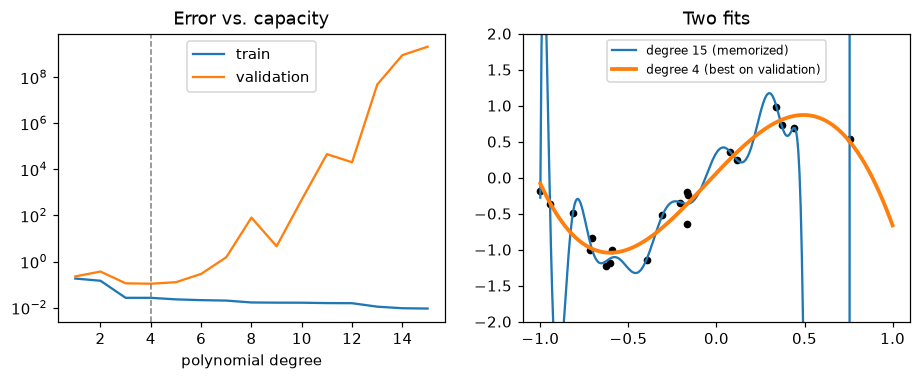

In [19]:
seed(1)
def make(n):
    x = np.random.uniform(-1, 1, n)
    return x, np.sin(3 * x) + np.random.normal(0, 0.25, n)
xtr, ytr = make(20); xva, yva = make(200)

degrees = range(1, 16)
tr_err, va_err, fits = [], [], {}
for d in degrees:
    coef = np.polyfit(xtr, ytr, d)
    tr_err.append(np.mean((np.polyval(coef, xtr) - ytr) ** 2))
    va_err.append(np.mean((np.polyval(coef, xva) - yva) ** 2))
    fits[d] = coef

best = degrees[int(np.argmin(va_err))]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.plot(degrees, tr_err, label='train'); a1.plot(degrees, va_err, label='validation')
a1.axvline(best, c='gray', ls='--', lw=1); a1.set(yscale='log', xlabel='polynomial degree', title='Error vs. capacity'); a1.legend()
xs = np.linspace(-1, 1, 300)
a2.scatter(xtr, ytr, c='k', s=16)
a2.plot(xs, np.polyval(fits[15], xs), c='C0', label='degree 15 (memorized)')
a2.plot(xs, np.polyval(fits[best], xs), c='C1', lw=2.5, label=f'degree {best} (best on validation)')
a2.set(ylim=(-2, 2), title='Two fits'); a2.legend(fontsize=8);



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 0.8 Benchmarks and leaderboards



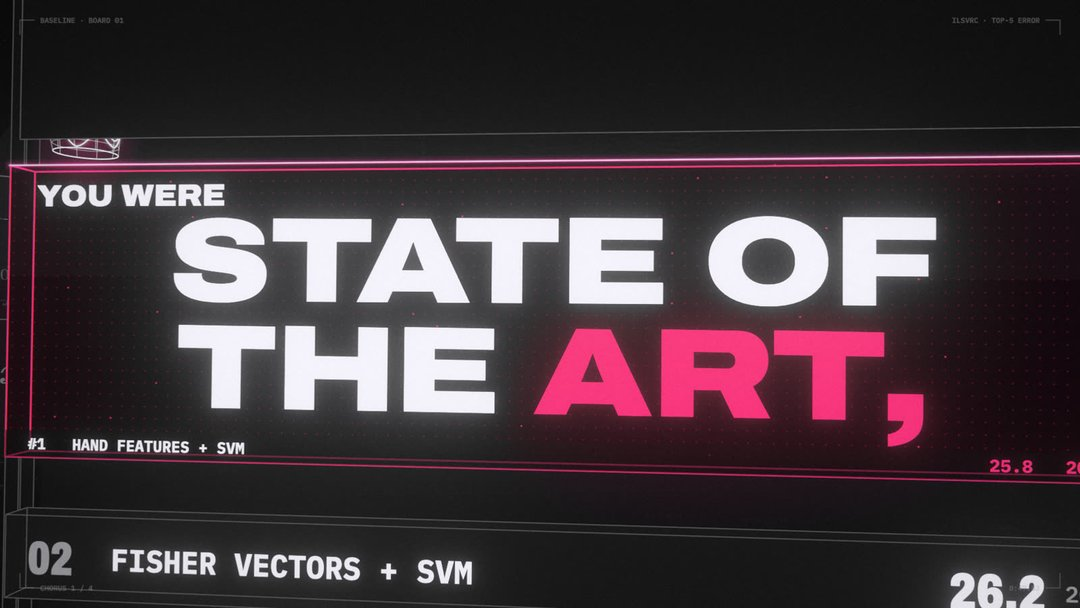

In [20]:
still(47.53)



The chorus is about **benchmarks**: a fixed public test set and a metric that everyone reports. ImageNet top-5 error, WMT14 BLEU, LAMBADA accuracy. Benchmarks are what let a field say "state of the art". They also have the weakness the song is about. A benchmark rewards whatever wins on it, and when everyone tunes against the same test set, it slowly turns into a validation set.



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

### Checkpoint
1. What are a parameter, a loss, and a gradient?
2. Write the five-line training loop from memory.
3. A model outputs scores (2.0, 0.5, −1.0) for three classes and the right answer is the first. Roughly what are the probabilities, and is the loss closer to 0 or to 1?
4. Why train on mini-batches instead of the whole dataset at once?
5. Why do you need a validation set separate from the test set?

<details><summary>Answers</summary>

1. A parameter is one tunable number in the model. The loss is one number that measures how wrong the model is. The gradient says, for every parameter, which direction (and how strongly) changes the loss.
2. `loss = loss_fn(model(x), y)` → `opt.zero_grad()` → `loss.backward()` → `opt.step()`, repeated. (The forward pass is inside the first line.)
3. About (0.79, 0.18, 0.04). The loss is −log 0.79 ≈ 0.24, so closer to 0.
4. Each step is far cheaper, so you take many more steps for the same compute. A gradient from 32 random examples is noisy but points roughly the right way, and the noise even helps a little.
5. You choose settings by looking at the validation score, so it gets tuned too. The test set must stay unseen to give an honest final number.
</details>

**Next:** Module 1, where the model stops being a line.